# Healthcare Analytics: Doctor Visits Study
**Course / Lab Project Submission**

### 1. Dataset Overview & Objective
This dataset contains records of patients, their health conditions, financial background, healthcare support, and physician consultations. The primary objective is to analyze patient attributes to identify which factors (illness, income, health condition, chronic issues, and insurance support) are associated with doctor visit frequency.

### 2. Column Grouping & Categorization:
* **Personal Information:** `gender`, `age`
* **Financial Information:** `income`
* **Health Information:** `illness`, `health`, `reduced` (days affected), `nchronic`, `lchronic`
* **Healthcare Support:** `private`, `freepoor`, `freerepat`
* **Doctor Visit Information (Target):** `visits`
* **Record Identifier:** `Unnamed: 0` (dropped during preprocessing)

### 3. Meaning of Healthcare Analytics:
Studying healthcare-related data to uncover utilization patterns and support data-driven decision-making in patient care and clinical resource allocation.

In [5]:
# Cell 1: Importing required data science libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Suppress unnecessary warnings
import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [7]:
# Cell 2: Loading dataset and basic inspection
df = pd.read_csv('1776250375-P2-Healthcare Analytics for Doctor Visits (1).csv')

# Display shape
print(f"Total rows: {df.shape[0]}, Total columns: {df.shape[1]}")

# Display first 5 rows
print("\n--- First 5 Rows ---")
print(df.head())

# Display dataset summary information
print("\n--- Dataset Info ---")
df.info()

Total rows: 5190, Total columns: 13

--- First 5 Rows ---
   Unnamed: 0  visits  gender   age  income  illness  reduced  health private  \
0           1       1  female  0.19    0.55        1        4       1     yes   
1           2       1  female  0.19    0.45        1        2       1     yes   
2           3       1    male  0.19    0.90        3        0       0      no   
3           4       1    male  0.19    0.15        1        0       0      no   
4           5       1    male  0.19    0.45        2        5       1      no   

  freepoor freerepat nchronic lchronic  
0       no        no       no       no  
1       no        no       no       no  
2       no        no       no       no  
3       no        no       no       no  
4       no        no      yes       no  

--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5190 entries, 0 to 5189
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  ----- 

In [8]:
# Cell 3: Check for nulls and duplicate rows
print("Missing values per column:")
print(df.isnull().sum())

print("\nDuplicate rows count:", df.duplicated().sum())

# Display descriptive statistics of numeric features
print("\n--- Summary Statistics ---")
print(df.describe())

Missing values per column:
Unnamed: 0    0
visits        0
gender        0
age           0
income        0
illness       0
reduced       0
health        0
private       0
freepoor      0
freerepat     0
nchronic      0
lchronic      0
dtype: int64

Duplicate rows count: 0

--- Summary Statistics ---
        Unnamed: 0       visits          age       income      illness  \
count  5190.000000  5190.000000  5190.000000  5190.000000  5190.000000   
mean   2595.500000     0.301734     0.406385     0.583160     1.431985   
std    1498.368279     0.798134     0.204782     0.368907     1.384152   
min       1.000000     0.000000     0.190000     0.000000     0.000000   
25%    1298.250000     0.000000     0.220000     0.250000     0.000000   
50%    2595.500000     0.000000     0.320000     0.550000     1.000000   
75%    3892.750000     0.000000     0.620000     0.900000     2.000000   
max    5190.000000     9.000000     0.720000     1.500000     5.000000   

           reduced       health 

In [13]:
# 3) Total number of illness and gender counts
print("Illness value counts:")
print(df['illness'].value_counts())

print("\nGender value counts:")
print(df['gender'].value_counts())

Illness value counts:
illness
1    1638
0    1554
2     946
3     542
4     274
5     236
Name: count, dtype: int64

Gender value counts:
gender
female    2702
male      2488
Name: count, dtype: int64


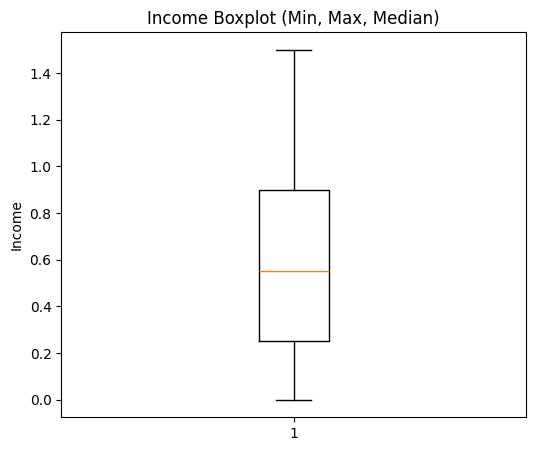

In [14]:
# 4) Visualize min, max, median of income
y = list(df.income)
plt.figure(figsize=(6, 5))
plt.boxplot(y)
plt.title('Income Boxplot (Min, Max, Median)')
plt.ylabel('Income')
plt.show()

In [15]:
# 5) Mean of reduced activity days grouped by gender
print("Mean reduced activity days by gender:")
print(df.groupby(['gender'])['reduced'].mean())

Mean reduced activity days by gender:
gender
female    0.975574
male      0.738344
Name: reduced, dtype: float64


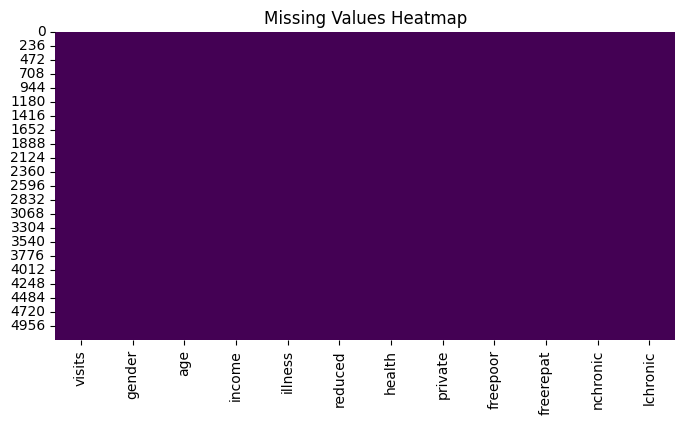

In [16]:
# 6) Missing values heatmap
plt.figure(figsize=(8, 4))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title('Missing Values Heatmap')
plt.show()

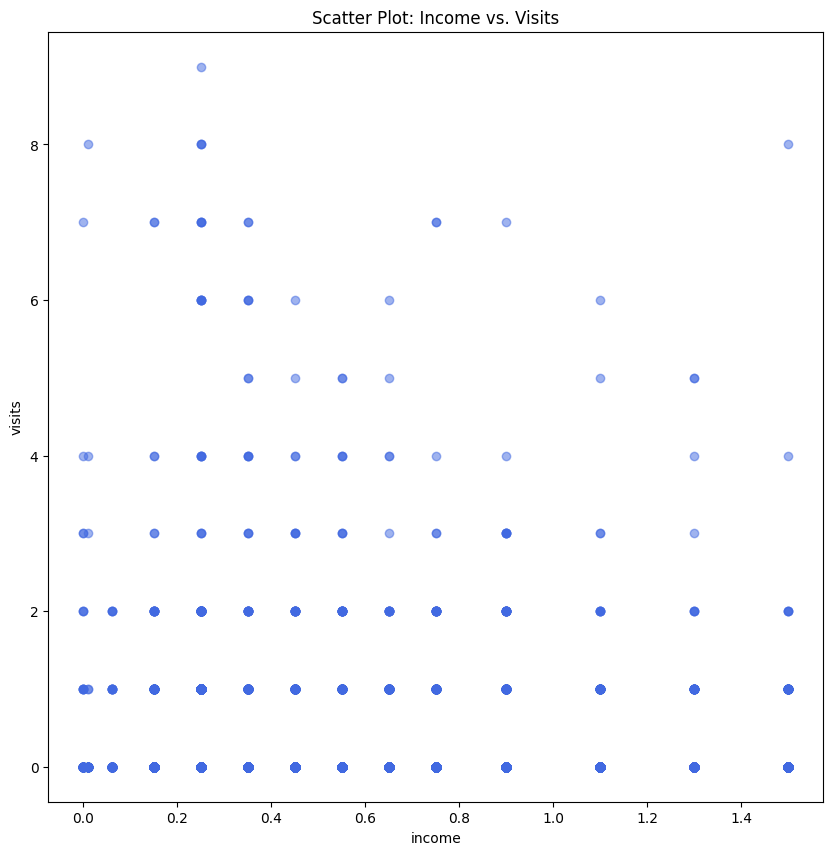

In [18]:
# 8) Scatter plot for Income vs Doctor Visits
plt.figure(figsize=(10, 10))
plt.scatter(x='income', y='visits', data=df, alpha=0.5, color='royalblue')
plt.xlabel('income')
plt.ylabel('visits')
plt.title('Scatter Plot: Income vs. Visits')
plt.show()

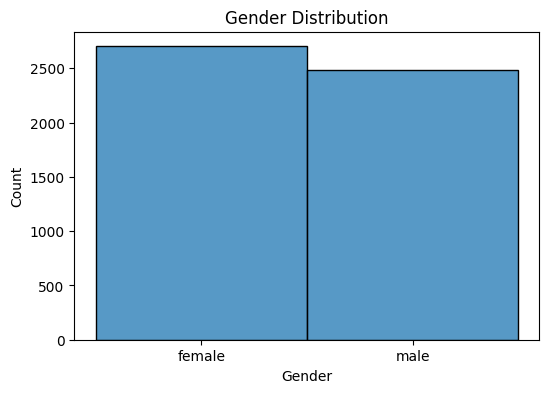

In [19]:
# 9) Count and visualize gender distribution
plt.figure(figsize=(6, 4))
sns.histplot(df.gender, bins=2)
plt.title('Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.show()

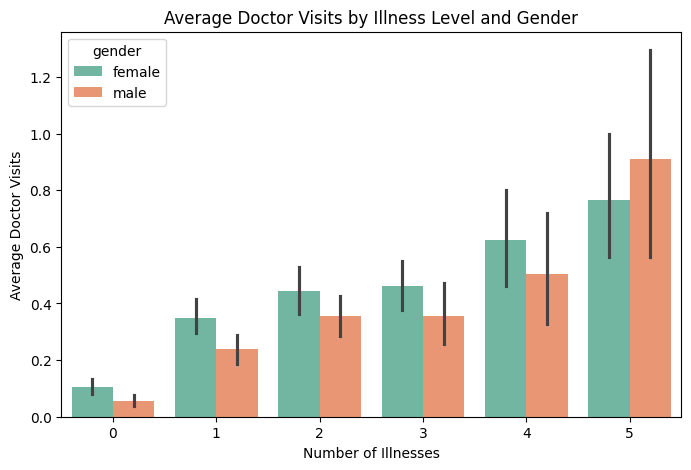

In [20]:
# 10) Visualize Doctor Visits across Illness levels / Insurance categories
plt.figure(figsize=(8, 5))
sns.barplot(x='illness', y='visits', hue='gender', data=df, palette='Set2')
plt.title('Average Doctor Visits by Illness Level and Gender')
plt.xlabel('Number of Illnesses')
plt.ylabel('Average Doctor Visits')
plt.show()

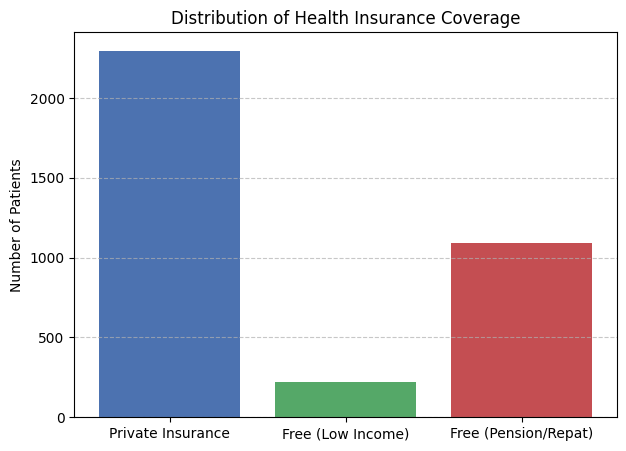

In [21]:
# 10) Visualize health insurance programs
insurance_counts = [
    df['private'].value_counts()['yes'],
    df['freepoor'].value_counts()['yes'],
    df['freerepat'].value_counts()['yes']
]
labels = ['Private Insurance', 'Free (Low Income)', 'Free (Pension/Repat)']

plt.figure(figsize=(7, 5))
plt.bar(labels, insurance_counts, color=['#4C72B0', '#55A868', '#C44E52'])
plt.title('Distribution of Health Insurance Coverage')
plt.ylabel('Number of Patients')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

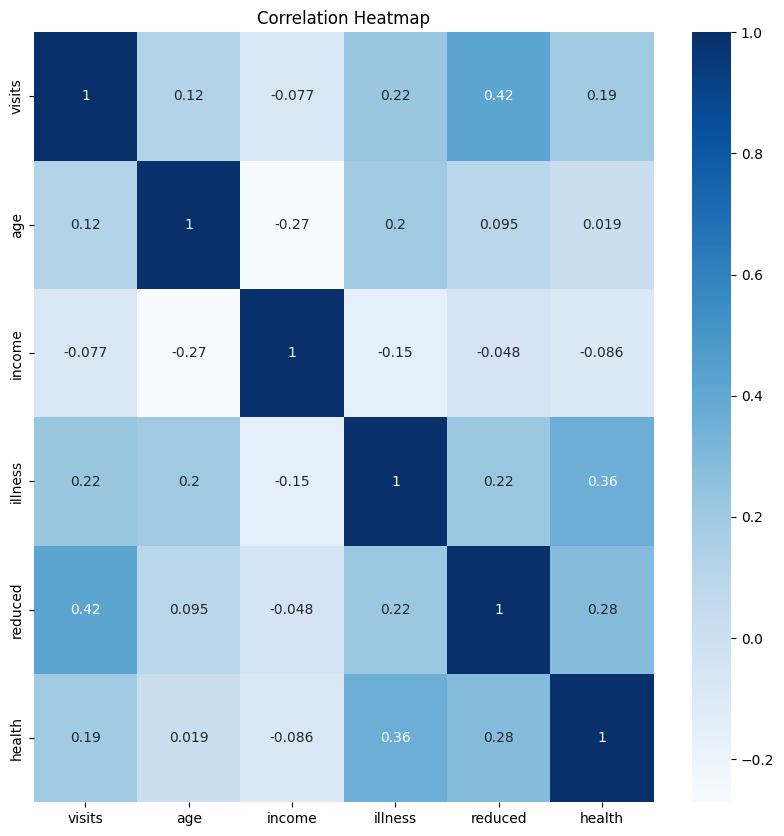

In [17]:
# 7) Correlation Heatmap
# Note: In latest pandas, set numeric_only=True so it doesn't give a TypeError on string columns
plt.figure(figsize=(10, 10))
sns.heatmap(df.corr(numeric_only=True), cbar=True, annot=True, cmap='Blues')
plt.title('Correlation Heatmap')
plt.show()

In [9]:
# Cell 4: Cleaning and encoding columns

# 1. Drop the redundant index column if it exists
if 'Unnamed: 0' in df.columns:
    df.drop(columns=['Unnamed: 0'], inplace=True)
    print("Dropped redundant column 'Unnamed: 0'")

# 2. Check unique values of categorical columns
categorical_cols = ['gender', 'private', 'freepoor', 'freerepat', 'nchronic', 'lchronic']
for col in categorical_cols:
    print(f"{col}: {df[col].unique()}")

# 3. Create a clean/encoded copy for analysis and machine learning
df_clean = df.copy()

# Map binary yes/no columns to 1/0
binary_cols = ['private', 'freepoor', 'freerepat', 'nchronic', 'lchronic']
for col in binary_cols:
    df_clean[col] = df_clean[col].map({'yes': 1, 'no': 0})

# Map gender: female = 0, male = 1
df_clean['gender'] = df_clean['gender'].map({'female': 0, 'male': 1})

# Display head of processed data
print("\n--- Cleaned & Encoded Data ---")
print(df_clean.head())

Dropped redundant column 'Unnamed: 0'
gender: ['female' 'male']
private: ['yes' 'no']
freepoor: ['no' 'yes']
freerepat: ['no' 'yes']
nchronic: ['no' 'yes']
lchronic: ['no' 'yes']

--- Cleaned & Encoded Data ---
   visits  gender   age  income  illness  reduced  health  private  freepoor  \
0       1       0  0.19    0.55        1        4       1        1         0   
1       1       0  0.19    0.45        1        2       1        1         0   
2       1       1  0.19    0.90        3        0       0        0         0   
3       1       1  0.19    0.15        1        0       0        0         0   
4       1       1  0.19    0.45        2        5       1        0         0   

   freerepat  nchronic  lchronic  
0          0         0         0  
1          0         0         0  
2          0         0         0  
3          0         0         0  
4          0         1         0  


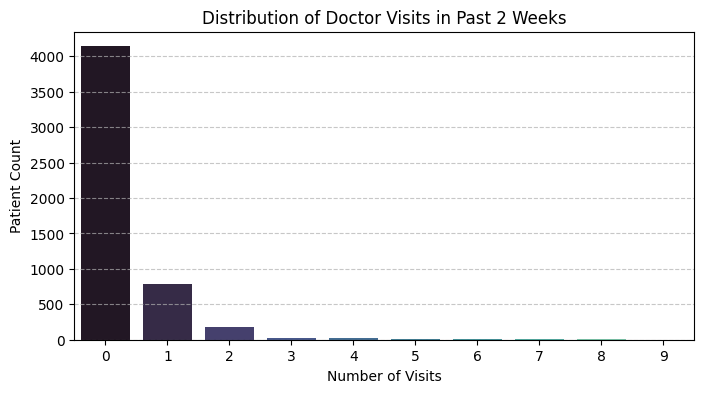

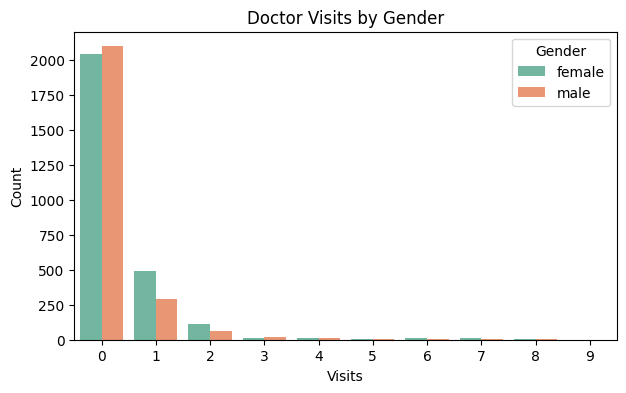

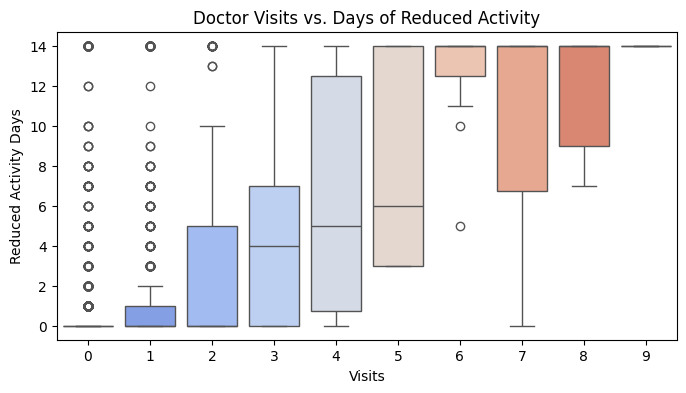

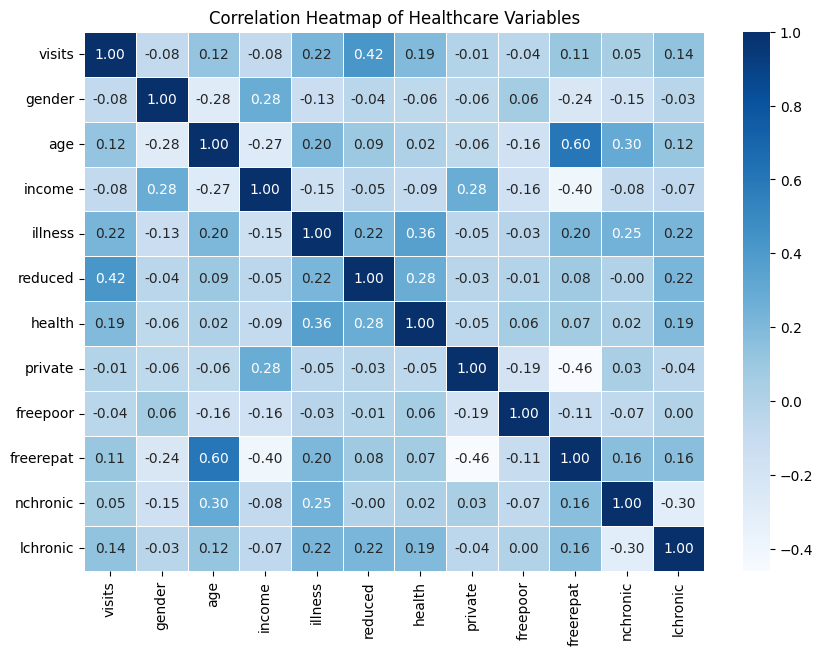

In [10]:
# Cell 5: Generating visual charts for the report

# 1. Target Variable Distribution: Doctor Visits
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x='visits', palette='mako')
plt.title('Distribution of Doctor Visits in Past 2 Weeks')
plt.xlabel('Number of Visits')
plt.ylabel('Patient Count')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# 2. Doctor Visits by Gender
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x='visits', hue='gender', palette='Set2')
plt.title('Doctor Visits by Gender')
plt.xlabel('Visits')
plt.ylabel('Count')
plt.legend(title='Gender')
plt.show()

# 3. Correlation between Illness, Reduced Activity, and Visits
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x='visits', y='reduced', palette='coolwarm')
plt.title('Doctor Visits vs. Days of Reduced Activity')
plt.xlabel('Visits')
plt.ylabel('Reduced Activity Days')
plt.show()

# 4. Correlation Heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(df_clean.corr(), annot=True, fmt='.2f', cmap='Blues', linewidths=0.5)
plt.title('Correlation Heatmap of Healthcare Variables')
plt.show()

Model Accuracy: 78.42%

--- Classification Report ---
              precision    recall  f1-score   support

No Visit (0)       0.82      0.92      0.87       808
 Visited (1)       0.52      0.30      0.38       230

    accuracy                           0.78      1038
   macro avg       0.67      0.61      0.63      1038
weighted avg       0.76      0.78      0.76      1038



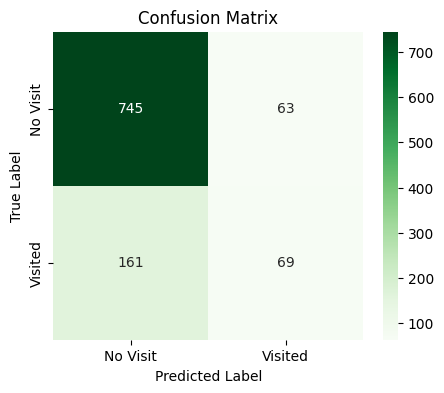

In [11]:
# Cell 6: Train-Test Split and Model Training
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Task: Classify whether a patient requires a doctor visit (visits > 0)
X = df_clean.drop(columns=['visits'])
y = (df_clean['visits'] > 0).astype(int)  # 0 = No Visit, 1 = Visited Doctor

# Split data into 80% train and 20% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize and train Random Forest Classifier
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Make predictions on test set
y_pred = model.predict(X_test)

# Evaluation metrics
acc = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {acc * 100:.2f}%\n")
print("--- Classification Report ---")
print(classification_report(y_test, y_pred, target_names=['No Visit (0)', 'Visited (1)']))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=['No Visit', 'Visited'],
            yticklabels=['No Visit', 'Visited'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

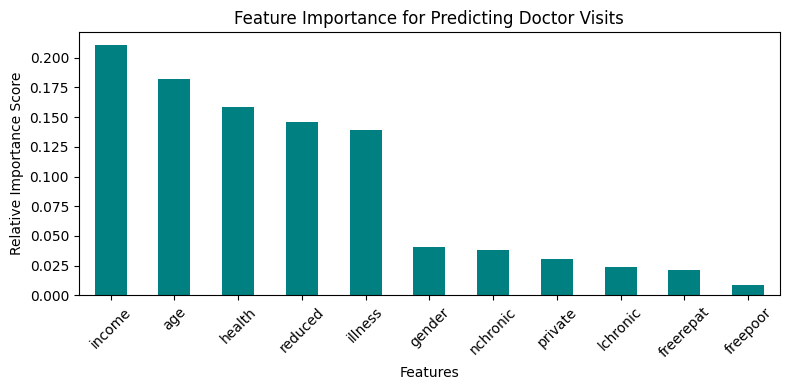

In [12]:
# Cell 7: Plotting which factors most influence doctor visits
feature_importances = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(8, 4))
feature_importances.plot(kind='bar', color='teal')
plt.title('Feature Importance for Predicting Doctor Visits')
plt.ylabel('Relative Importance Score')
plt.xlabel('Features')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()